# 03 — Exploratory Data Analysis (Phases 5–9)

**Workflow stages covered:** `13` EDA (univariate) · `14` temporal analysis ·
`15` spatial analysis · `16` target–feature analysis · `17` correlation analysis ·
`18` multicollinearity / redundancy.

**This notebook is read-only.** It never writes to `data/`; figures go to `figures/phase5_*`,
the verdict goes to `reports/phase5_eda.md`.

**Decisions baked in (Phase 0 §9):**
* **D1** monsoon = **JJAS** · **D2** all three horizons reported equally.
* **D5** label drift must be decomposed into *within-station change* vs *network composition*
  (fixed panel of stations vs all stations) — a pooled metric would be a moving target.
* **D6** missing days must be tested for informative missingness (are unobserved days
  seasonally / hazard biased?).
* **D7** the persistence baseline (`wl_pct_danger` alone) is computed here, per horizon and
  per year — every later model result must be reported next to it.

**Contracts inherited from Phase 0:** label contract (`1` if danger reached in `(t, t+h]`,
`0` only on fully observed windows, `NaN` otherwise); information boundary
(`obs_days_*` are labels-adjacent and are **never** features); raw data untouched.

In [1]:
%matplotlib inline
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, chi2_contingency

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 300)
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white",
                     "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path("..").resolve()
if not (ROOT / "data").exists():
    ROOT = Path(".").resolve()
FULL_P = ROOT / "data" / "processed" / "flood_dataset.csv"
MR_P   = ROOT / "data" / "processed" / "flood_dataset_model_ready.csv"
ST_P   = ROOT / "data" / "raw" / "ffwc" / "ffwc_stations.csv"
FIG    = ROOT / "figures"
FIG.mkdir(exist_ok=True)

checks, findings = [], []

def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if bool(ok) else "FAIL", "detail": str(detail)})
    print(("[PASS] " if ok else "[FAIL] ") + name + (f"  ({detail})" if detail else ""))
    return bool(ok)

def note(tag, text):
    findings.append({"id": tag, "finding": text})
    print(f"[NOTE {tag}] {text}")

def savefig(fig, name):
    p = FIG / name
    fig.savefig(p, bbox_inches="tight")
    print("figure ->", p.relative_to(ROOT))

HORIZONS = ["24h", "48h", "72h"]
LAB = {h: f"label_{h}" for h in HORIZONS}

print("root:", ROOT)

root: D:\Flood predictor


---
## Stage 13 — Univariate analysis (Phase 5)
Distribution, moments, quantiles and outliers for the variables that carry the phenomenon.

In [2]:
full = pd.read_csv(FULL_P, parse_dates=["date"])
mr = pd.read_csv(MR_P, parse_dates=["date"])
mr["year"] = mr.date.dt.year
mr["month"] = mr.date.dt.month
mr["monsoon"] = mr.month.isin([6, 7, 8, 9])
full["year"] = full.date.dt.year
full["month"] = full.date.dt.month

KEY = ["wl_last", "wl_max", "wl_dist_to_danger", "wl_pct_danger", "wl_rise_1d",
       "wl_max_roll7", "rain_1d", "rain_7d", "rain_30d", "wet_days_7",
       "tmax_c", "tmin_c"]

q = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
uni = pd.DataFrame({
    "n":   mr[KEY].count(),
    "nan": mr[KEY].isna().sum(),
    "mean": mr[KEY].mean(),
    "std":  mr[KEY].std(),
    "min":  mr[KEY].min(),
})
qs = mr[KEY].quantile(q).T                      # rows = features, cols = quantile levels
qs.columns = [f"p{int(v*100):02d}" for v in qs.columns]
uni = uni.join(qs)
uni["max"] = mr[KEY].max()
print("univariate summary (model-ready):")
print(uni.round(3).to_string())

iqr = uni["p75"] - uni["p25"]
lo, hi = uni["p25"] - 1.5 * iqr, uni["p75"] + 1.5 * iqr
out = pd.DataFrame({
    "below_fence": [int((mr[c] < lo[c]).sum()) for c in KEY],
    "above_fence": [int((mr[c] > hi[c]).sum()) for c in KEY],
}, index=KEY)
print("\nIQR-fence outliers (right-skewed rainfall makes these expected, not errors):")
print(out.to_string())

finite_ok = bool(np.isfinite(uni[["mean", "std", "min", "max"]].to_numpy()).all())
check("U1 univariate stats finite for all 12 key variables", finite_ok,
      f"{int(uni['n'].min())}..{int(uni['n'].max())} non-null")
check("U2 every key variable non-constant (std > 0)", bool((uni["std"] > 0).all()))

univariate summary (model-ready):
                        n   nan     mean      std     min     p01     p05      p25     p50      p75      p95       p99       max
wl_last            200665     0   10.566   11.108  -2.030   0.310   1.060    3.370    7.02   13.580   28.540    64.540    70.810
wl_max             200665     0   10.686   11.049  -0.610   0.810   1.460    3.500    7.09   13.630   28.590    64.550    70.810
wl_dist_to_danger  200665     0    3.264    2.457  -4.450  -0.820   0.000    1.410    2.85    4.740    8.050    10.160    12.260
wl_pct_danger      200665     0    0.695    0.244  -0.147   0.127   0.237    0.531    0.74    0.889    1.000     1.127     1.833
wl_rise_1d         199670   995    0.006    0.337  -5.960  -0.920  -0.350   -0.090   -0.01    0.070    0.410     1.150     7.790
wl_max_roll7       198125  2540   10.693   11.051   0.028   0.849   1.477    3.491    7.12   13.620   28.603    64.589    68.976
rain_1d            200421   244   12.934   19.575   0.000   0.0

True

figure -> figures\phase5_univariate.png


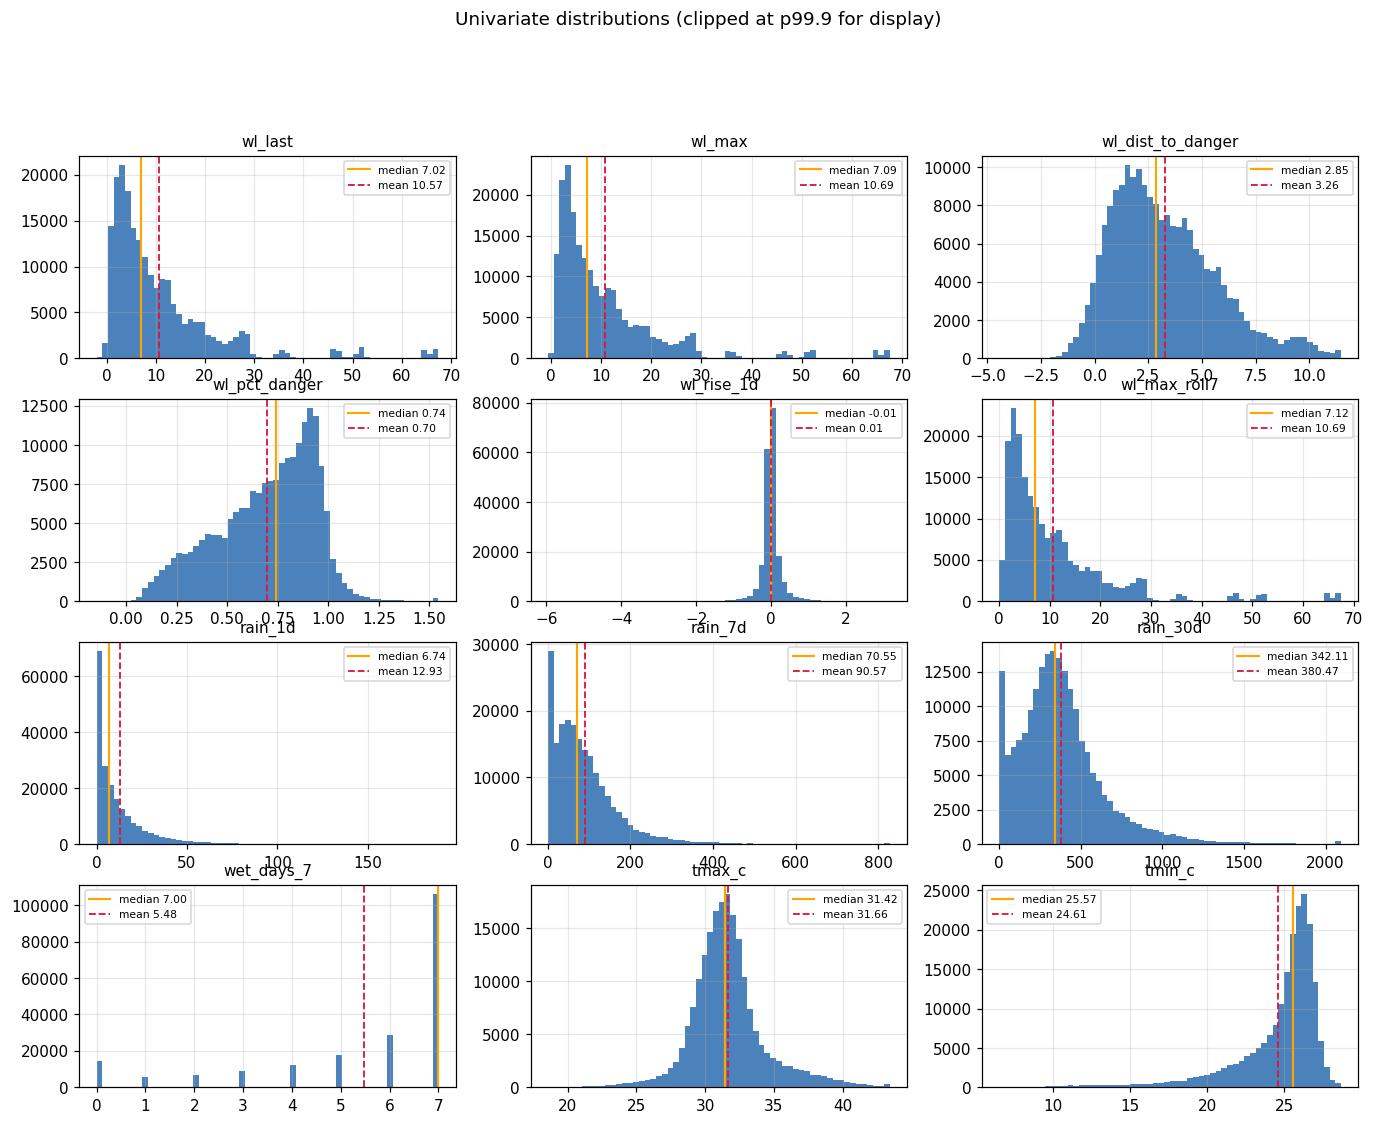

In [3]:
fig, axes = plt.subplots(4, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), KEY):
    v = mr[c].dropna()
    clip = v.clip(upper=v.quantile(0.999))
    ax.hist(clip, bins=60, color="#2b6cb0", alpha=0.85)
    ax.axvline(v.median(), color="orange", lw=1.4, label=f"median {v.median():.2f}")
    ax.axvline(v.mean(), color="crimson", lw=1.2, ls="--", label=f"mean {v.mean():.2f}")
    ax.set_title(c, fontsize=10)
    ax.legend(fontsize=7)
fig.suptitle("Univariate distributions (clipped at p99.9 for display)", y=1.0)
savefig(fig, "phase5_univariate.png")
plt.show()

---
## Stage 14 — Temporal analysis (Phase 6)
Flood frequency over time, seasonality (monsoon = **JJAS**, decision D1), episodes, and the
observation process itself (decisions **D5** drift decomposition, **D6** informative missingness).

In [4]:
rows = []
for h in HORIZONS:
    s = mr.loc[mr[LAB[h]].notna(), ["year", "month"]].copy()
    s["h"] = h
    s["label"] = mr.loc[s.index, LAB[h]]
    rows.append(s)
lab = pd.concat(rows, ignore_index=True)

mon_freq = (lab.groupby(["month", "h"]).label.agg(["size", "sum", "mean"])
               .rename(columns={"size": "n", "sum": "pos", "mean": "rate"}).round(4))
yr_freq = (lab.groupby(["year", "h"]).label.agg(["size", "sum", "mean"])
              .rename(columns={"size": "n", "sum": "pos", "mean": "rate"}).round(4))

tot_ok = all(int(mon_freq.xs(h, level="h").n.sum()) == int(mr[LAB[h]].notna().sum())
             for h in HORIZONS)
check("TM1 monthly frequency table partitions every labelled row (per horizon)", tot_ok,
      f"24h n={int(mon_freq.xs('24h', level='h').n.sum()):,}")

mrows = []
for h in HORIZONS:
    s = mr[mr[LAB[h]].notna()]
    for key, sub in (("monsoon(JJAS)", s[s.monsoon]), ("non-monsoon", s[~s.monsoon])):
        mrows.append({"h": h, "season": key, "n": len(sub),
                      "pos": int(sub[LAB[h]].sum()), "rate": round(sub[LAB[h]].mean(), 4)})
season = pd.DataFrame(mrows)
part_ok = all(int(season[season.h == h].n.sum()) == int(mr[LAB[h]].notna().sum())
              for h in HORIZONS)
check("TM2 D1 monsoon flag (JJAS) partitions every labelled row exactly once", part_ok)

print("\nmonthly flood frequency (rate = mean label):")
print(mon_freq.unstack("h").to_string())
print("\nyearly flood frequency:")
print(yr_freq.unstack("h").to_string())
print("\nmonsoon vs non-monsoon (decision D1):")
print(season.to_string(index=False))

[PASS] TM1 monthly frequency table partitions every labelled row (per horizon)  (24h n=200,559)


[PASS] TM2 D1 monsoon flag (JJAS) partitions every labelled row exactly once

monthly flood frequency (rate = mean label):
           n                   pos                    rate                
h        24h    48h    72h     24h     48h     72h     24h     48h     72h
month                                                                     
1       1438   1286   1185     0.0     0.0     0.0  0.0000  0.0000  0.0000
2       2123   1965   1862     0.0     0.0     0.0  0.0000  0.0000  0.0000
3       7296   7100   6921    16.0    26.0    33.0  0.0022  0.0037  0.0048
4      20751  20569  20397   161.0   193.0   218.0  0.0078  0.0094  0.0107
5      26264  26055  25873   296.0   382.0   463.0  0.0113  0.0147  0.0179
6      26594  26394  26186  1168.0  1423.0  1637.0  0.0439  0.0539  0.0625
7      28329  28205  28085  3005.0  3327.0  3602.0  0.1061  0.1180  0.1283
8      28623  28548  28474  2845.0  3127.0  3381.0  0.0994  0.1095  0.1187
9      27789  27753  27730  1809.0  2009.0  2192.0  

[NOTE E1-24h] flood episodes (24h): 1,315 runs, median 3 d, p90 18 d, longest 144 d
[NOTE E1-48h] flood episodes (48h): 1,214 runs, median 5 d, p90 21 d, longest 145 d


[NOTE E1-72h] flood episodes (72h): 1,164 runs, median 6 d, p90 24 d, longest 146 d

extreme-rainfall days (rain_7d > p99 = 424 mm): 2,007 station-days across 327 calendar days


figure -> figures\phase5_temporal.png


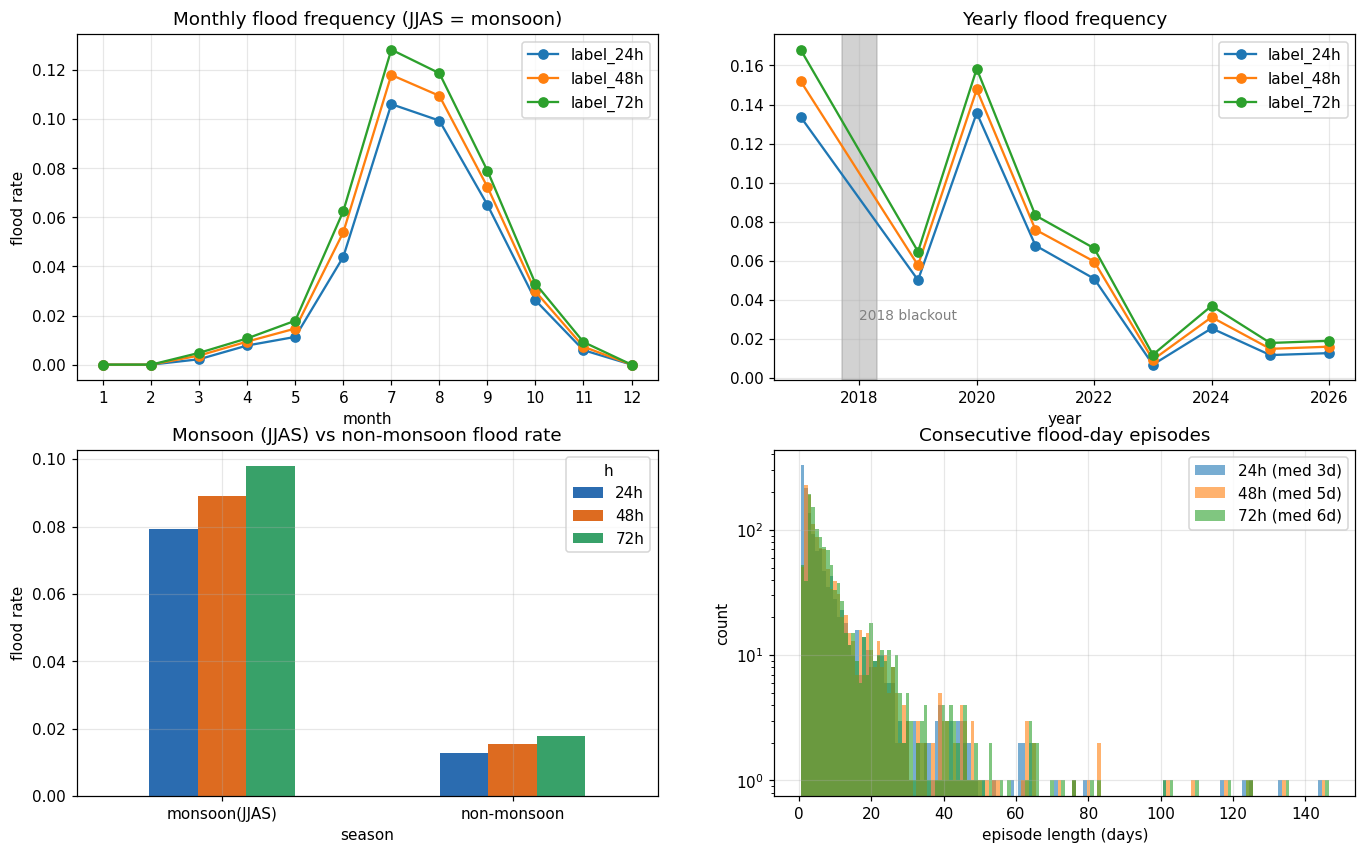

In [5]:
epi = {}
for h in HORIZONS:
    d = mr.loc[mr[LAB[h]].notna(), ["station_id", "date", LAB[h]]].sort_values(["station_id", "date"])
    pos = (d[LAB[h]] == 1).astype(int)
    newrun = (pos != pos.shift()) | (d.date.diff().dt.days != 1)
    gid = newrun.cumsum()
    runs = pos.groupby(gid).agg(["first", "size"])
    runs = runs[runs["first"] == 1]["size"]
    epi[h] = runs
    note(f"E1-{h}", f"flood episodes ({h}): {len(runs):,} runs, median {runs.median():.0f} d, "
                    f"p90 {runs.quantile(0.9):.0f} d, longest {runs.max():.0f} d")

p99 = mr.rain_7d.quantile(0.99)
ext = mr[mr.rain_7d > p99]
print(f"\nextreme-rainfall days (rain_7d > p99 = {p99:.0f} mm): {len(ext):,} station-days "
      f"across {ext.date.nunique():,} calendar days")

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
ax = axes[0, 0]
for h in HORIZONS:
    r = mon_freq.xs(h, level="h")
    ax.plot(r.index, r.rate, marker="o", label=f"label_{h}")
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("flood rate")
ax.set_title("Monthly flood frequency (JJAS = monsoon)"); ax.legend()
ax = axes[0, 1]
for h in HORIZONS:
    r = yr_freq.xs(h, level="h")
    ax.plot(r.index, r.rate, marker="o", label=f"label_{h}")
ax.axvspan(2017.7, 2018.3, color="grey", alpha=0.35)
ax.annotate("2018 blackout", xy=(2018, 0.03), fontsize=9, color="grey")
ax.set_title("Yearly flood frequency"); ax.set_xlabel("year"); ax.legend()
ax = axes[1, 0]
pv = season.pivot(index="season", columns="h", values="rate")
pv.plot.bar(ax=ax, color=["#2b6cb0", "#dd6b20", "#38a169"])
ax.set_title("Monsoon (JJAS) vs non-monsoon flood rate"); ax.set_ylabel("flood rate")
ax.tick_params(axis="x", rotation=0)
ax = axes[1, 1]
for h in HORIZONS:
    ax.hist(epi[h], bins=np.arange(0.5, epi[h].max() + 1.5, 1), alpha=0.6,
            label=f"{h} (med {epi[h].median():.0f}d)")
ax.set_yscale("log"); ax.set_xlabel("episode length (days)"); ax.set_ylabel("count")
ax.set_title("Consecutive flood-day episodes"); ax.legend()
savefig(fig, "phase5_temporal.png")
plt.show()

### D5 — decomposing the label drift (decision)
Pooled base rates fall more than 10× from 2017 to 2023. Is the *flood regime* changing at
the stations, or is the *network* changing (85 → 133 stations, different rivers, different
danger levels)? We compare all stations against a **fixed panel** of stations that were
fully reporting *and* producing labels in every year.

fixed panel: 31 stations with >=200 observed days AND labels in EVERY year 2017..2026 (2018 excluded - network blackout)
stations with data per year: {2017: 86, 2019: 86, 2020: 95, 2021: 106, 2022: 106, 2023: 109, 2024: 110, 2025: 128, 2026: 141}


[PASS] TM3 D5 drift decomposition built for every horizon x year (all vs fixed panel)  (27 rows, panel=31 stations)

h        24h     48h     72h
year                        
2017  0.1337  0.1520  0.1681
2019  0.0501  0.0577  0.0647
2020  0.1357  0.1477  0.1583
2021  0.0678  0.0759  0.0832
2022  0.0508  0.0596  0.0664
2023  0.0068  0.0093  0.0119
2024  0.0254  0.0311  0.0369
2025  0.0117  0.0149  0.0179
2026  0.0127  0.0160  0.0190   <- all stations

h        24h     48h     72h
year                        
2017  0.1510  0.1765  0.1980
2019  0.0279  0.0340  0.0401
2020  0.0586  0.0672  0.0751
2021  0.0162  0.0198  0.0236
2022  0.0321  0.0392  0.0449
2023  0.0032  0.0046  0.0060
2024  0.0253  0.0323  0.0394
2025  0.0052  0.0069  0.0086
2026  0.0034  0.0051  0.0068   <- fixed panel
[NOTE E2] D5 verdict (72h): pooled base rate falls 14.9 pp (2017 -> 2026), fixed-panel fall 19.1 pp -> mostly WITHIN-station (real regime change); composition contributes -4.2 pp; supports D8 (per-year reporti

figure -> figures\phase5_drift_decomposition.png


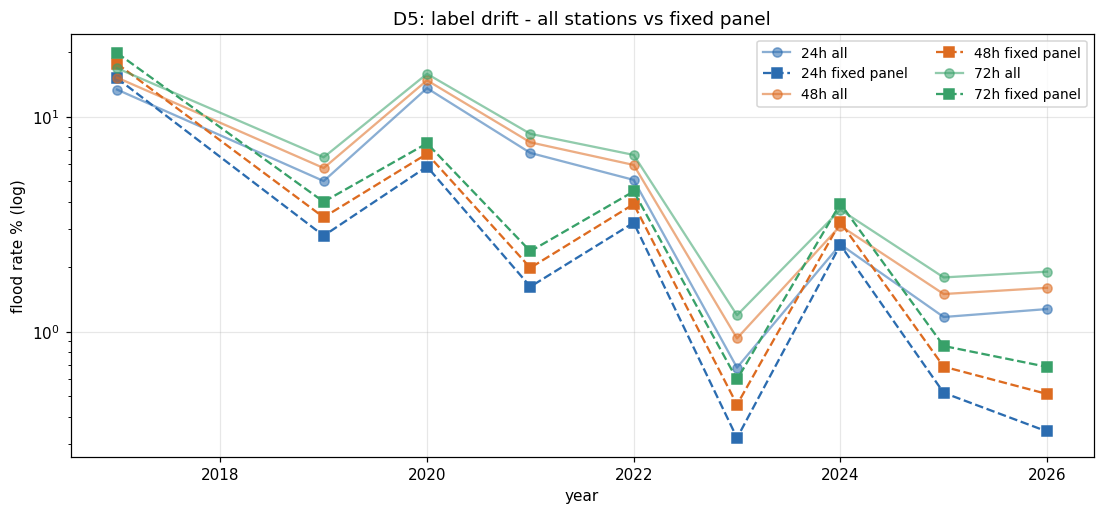

In [6]:
years = sorted(full.year.unique())
years = [y for y in years if y != 2018]
obs_by = (full[full.year != 2018]
          .groupby(["station_id", "year"]).day_observed.sum().unstack("year"))
obs_ok = obs_by[years].ge(200).all(axis=1)
lab_years = (mr[mr[LAB["72h"]].notna()].groupby("station_id").year.nunique()
             .reindex(obs_by.index).fillna(0))
panel_ids = obs_by.index[obs_ok & lab_years.eq(len(years))]
net = (full[full.day_observed == 1].groupby("year").station_id.nunique())
print(f"fixed panel: {len(panel_ids)} stations with >=200 observed days AND labels in EVERY "
      f"year {years[0]}..{years[-1]} (2018 excluded - network blackout)")
print("stations with data per year:", {int(k): int(v) for k, v in net.items() if v > 0})

d5 = []
for h in HORIZONS:
    s = mr[mr[LAB[h]].notna()]
    for y, g in s.groupby("year"):
        p = g[g.station_id.isin(panel_ids)]
        d5.append({"h": h, "year": y, "n_all": len(g), "rate_all": g[LAB[h]].mean(),
                   "n_panel": len(p), "rate_panel": p[LAB[h]].mean() if len(p) else np.nan})
d5 = pd.DataFrame(d5)
ok5 = (d5.groupby("h").year.nunique().eq(len(years)).all()
       and d5[["rate_all"]].notna().all().all()
       and d5[d5.year.isin(years)]["rate_panel"].notna().all())
check("TM3 D5 drift decomposition built for every horizon x year (all vs fixed panel)",
      ok5, f"{len(d5)} rows, panel={len(panel_ids)} stations")
print()
print(d5.pivot(index="year", columns="h", values="rate_all").round(4).to_string(),
      "  <- all stations")
print()
print(d5.pivot(index="year", columns="h", values="rate_panel").round(4).to_string(),
      "  <- fixed panel")

d = d5[d5.h == "72h"].set_index("year")
fall_all = d.loc[years[0], "rate_all"] - d.loc[years[-1], "rate_all"]
fall_panel = d.loc[years[0], "rate_panel"] - d.loc[years[-1], "rate_panel"]
within = abs(fall_panel) < abs(fall_all) / 2
note("E2", f"D5 verdict (72h): pooled base rate falls {fall_all*100:.1f} pp "
           f"({years[0]} -> {years[-1]}), fixed-panel fall {fall_panel*100:.1f} pp -> "
           f"{'COMPOSITION-driven (network changed more than the rivers)' if within else 'mostly WITHIN-station (real regime change)'}; "
           f"composition contributes {(abs(fall_all) - abs(fall_panel))*100:.1f} pp; "
           f"supports D8 (per-year reporting, rolling origin)")

fig, ax = plt.subplots(figsize=(12, 5))
for h, c in zip(HORIZONS, ["#2b6cb0", "#dd6b20", "#38a169"]):
    r = d5[d5.h == h]
    ax.plot(r.year, r.rate_all * 100, marker="o", color=c, alpha=0.55, label=f"{h} all")
    ax.plot(r.year, r.rate_panel * 100, marker="s", ls="--", color=c, label=f"{h} fixed panel")
ax.set_yscale("log"); ax.set_xlabel("year"); ax.set_ylabel("flood rate % (log)")
ax.set_title("D5: label drift - all stations vs fixed panel"); ax.legend(ncol=2, fontsize=9)
savefig(fig, "phase5_drift_decomposition.png")
plt.show()

### D6 — is the observation process informative? (decision)
The label is `NaN` whenever the window is not fully observed. If unobserved days are
concentrated in the monsoon, or on rainy days, then *the rows we can train on are a biased
sample of flood risk* — and no model can fix that silently. Effect sizes (not p-values:
n ≈ 330k makes every p-value significant) decide the verdict.

[PASS] TM4 D6 observed-day rates computed for all 12 months (2018 excluded)
[PASS] TM5 D6 rain compared on observed vs unobserved days (KS on >=1000 rows each)
[NOTE E3] D6 verdict: observation rate monsoon 99.0% vs non-monsoon 44.7% (+54.3 pp); rain_30d observed-vs-unobserved KS=0.731 (median 340 vs 12 mm); month chi2 p=0.0e+00 -> observation is INFORMATIVE (seasonally/hazard biased): NaN days are a missingness process, never code them 0

% of station-days observed by month (2018 excluded):
month
1      6.3
2      9.7
3     28.6
4     78.3
5     95.1
6     98.1
7     99.0
8     99.4
9     99.5
10    98.1
11    26.2
12     5.4

rain_30d: observed n=208,325 median 339.8 mm vs unobserved n=117,535 median 12.2 mm


figure -> figures\phase5_observed_vs_unobserved.png


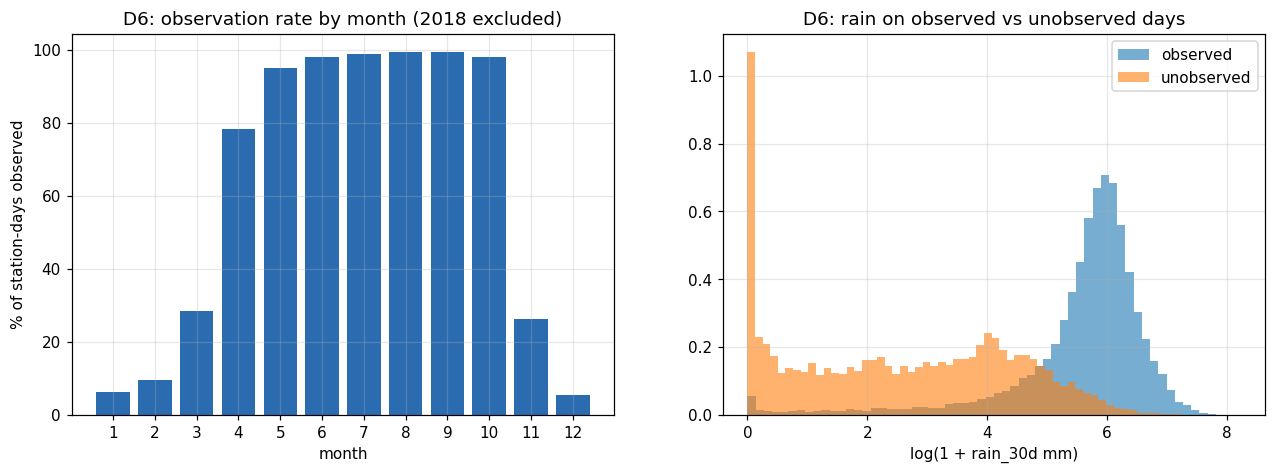

In [7]:
o = full[full.year != 2018].copy()
by_month = o.groupby("month").day_observed.agg(["size", "mean"])
cont = pd.crosstab(o.month, o.day_observed)
chi2, p_month, _, _ = chi2_contingency(cont)

o["monsoon"] = o.month.isin([6, 7, 8, 9])
r_obs = o.loc[o.day_observed == 1, "rain_30d"].dropna()
r_uno = o.loc[o.day_observed == 0, "rain_30d"].dropna()
ks = ks_2samp(r_obs, r_uno)

rate_m = o.loc[o.monsoon, "day_observed"].mean()
rate_n = o.loc[~o.monsoon, "day_observed"].mean()
pp = (rate_m - rate_n) * 100

check("TM4 D6 observed-day rates computed for all 12 months (2018 excluded)",
      len(by_month) == 12 and by_month["mean"].between(0, 1).all())
check("TM5 D6 rain compared on observed vs unobserved days (KS on >=1000 rows each)",
      len(r_obs) > 1000 and len(r_uno) > 1000 and np.isfinite(ks.statistic))

informative = (abs(pp) > 3.0) or (ks.statistic > 0.05)
note("E3", f"D6 verdict: observation rate monsoon {rate_m*100:.1f}% vs non-monsoon "
           f"{rate_n*100:.1f}% ({pp:+.1f} pp); rain_30d observed-vs-unobserved "
           f"KS={ks.statistic:.3f} (median {r_obs.median():.0f} vs {r_uno.median():.0f} mm); "
           f"month chi2 p={p_month:.1e} -> observation is "
           f"{'INFORMATIVE (seasonally/hazard biased): NaN days are a missingness process, never code them 0' if informative else 'essentially non-informative'}")

print("\n% of station-days observed by month (2018 excluded):")
print((by_month["mean"] * 100).round(1).to_string())
print(f"\nrain_30d: observed n={len(r_obs):,} median {r_obs.median():.1f} mm vs "
      f"unobserved n={len(r_uno):,} median {r_uno.median():.1f} mm")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(by_month.index, by_month["mean"] * 100, color="#2b6cb0")
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel("month")
axes[0].set_ylabel("% of station-days observed")
axes[0].set_title("D6: observation rate by month (2018 excluded)")
axes[1].hist(np.log1p(r_obs), bins=60, alpha=0.6, density=True, label="observed")
axes[1].hist(np.log1p(r_uno), bins=60, alpha=0.6, density=True, label="unobserved")
axes[1].set_xlabel("log(1 + rain_30d mm)")
axes[1].set_title("D6: rain on observed vs unobserved days"); axes[1].legend()
savefig(fig, "phase5_observed_vs_unobserved.png")
plt.show()

---
## Stage 15 — Spatial analysis (Phase 7)
Station-level and division-level flood geography. The interactive choropleth stays
**BLOCKED** (geopandas/folium deferred); a static lat/lon scatter is produced instead.

[PASS] SP1 every labelled station has a valid Bangladesh lat/lon  (133/133 stations carry labels)
[PASS] SP2 station-level rates built for all three horizons on the same station set  ({'24h': 133, '48h': 133, '72h': 133})
division-level flood frequency (label_72h):
            stations      n     pos    rate
division                                   
Barishal           2   2381   718.0  0.3016
Khulna             9  13952  2369.0  0.1698
Sylhet            26  31879  2329.0  0.0731
Chittagong         8   2534   149.0  0.0588
Rangpur           20  29034  1631.0  0.0562
Dhaka             28  45555  2412.0  0.0529
Rajshahi          17  29753  1550.0  0.0521
Mymensingh        10  16254   531.0  0.0327
Chattogram        13  23832   651.0  0.0273

top 12 stations by label_72h rate (n >= 200 labelled days):
       name   division    n   pos   rate
     Mongla     Khulna 1167 978.0 0.8380
     Khulna     Khulna 1649 862.0 0.5227
 Daulatkhan   Barishal 1187 479.0 0.4035
Companyganj Chittagong  3

figure -> figures\phase5_spatial.png


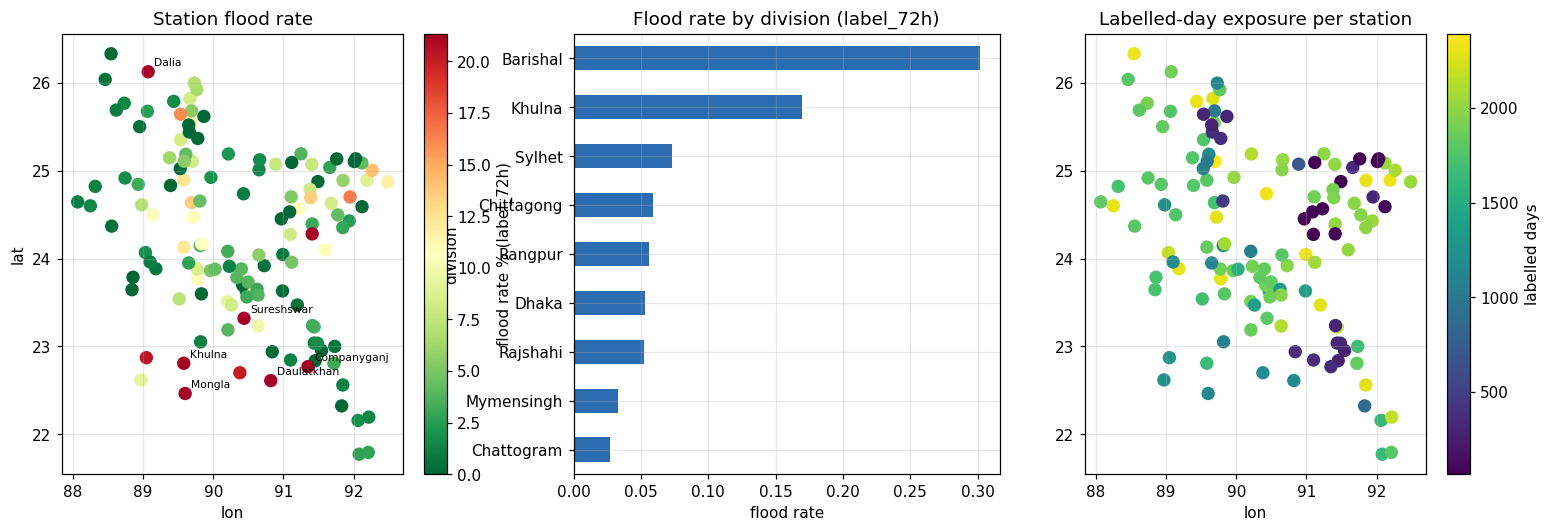

In [8]:
sp = []
for h in HORIZONS:
    s = mr[mr[LAB[h]].notna()]
    g = (s.groupby(["station_id", "name", "division", "lat", "lon"])
          .agg(n=(LAB[h], "size"), pos=(LAB[h], "sum")))
    g["rate"] = g.pos / g.n
    g["h"] = h
    sp.append(g.reset_index())
sp = pd.concat(sp, ignore_index=True)
sp72 = sp[sp.h == "72h"].copy()

n_mr_st = mr.station_id.nunique()
n_lab_st = mr.loc[mr[LAB["72h"]].notna(), "station_id"].nunique()
in_bbox = bool(sp72.lat.between(20.5, 27.0).all() and sp72.lon.between(87.5, 93.0).all())
check("SP1 every labelled station has a valid Bangladesh lat/lon", in_bbox,
      f"{n_lab_st}/{n_mr_st} stations carry labels")
check("SP2 station-level rates built for all three horizons on the same station set",
      sp.groupby("h").station_id.nunique().eq(sp72.station_id.nunique()).all(),
      f"{sp.groupby('h').station_id.nunique().to_dict()}")

div = (sp72.groupby("division")
       .agg(stations=("station_id", "nunique"), n=("n", "sum"), pos=("pos", "sum")))
div["rate"] = div.pos / div.n
print("division-level flood frequency (label_72h):")
print(div.sort_values("rate", ascending=False).round(4).to_string())

print("\ntop 12 stations by label_72h rate (n >= 200 labelled days):")
top = sp72[sp72.n >= 200].nlargest(12, "rate")[["name", "division", "n", "pos", "rate"]]
print(top.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
sc = axes[0].scatter(sp72.lon, sp72.lat, c=sp72.rate * 100, s=60,
                     cmap="RdYlGn_r", vmin=0, vmax=sp72.rate.quantile(0.95) * 100)
for _, r in sp72.nlargest(6, "rate").iterrows():
    axes[0].annotate(str(r["name"])[:14], (r.lon, r.lat), fontsize=7, xytext=(4, 4),
                     textcoords="offset points")
plt.colorbar(sc, ax=axes[0], label="flood rate % (label_72h)")
axes[0].set_title("Station flood rate"); axes[0].set_xlabel("lon"); axes[0].set_ylabel("lat")
div.sort_values("rate").plot.barh(y="rate", ax=axes[1], color="#2b6cb0", legend=False)
axes[1].set_title("Flood rate by division (label_72h)"); axes[1].set_xlabel("flood rate")
sc2 = axes[2].scatter(sp72.lon, sp72.lat, c=sp72.n, s=60, cmap="viridis")
plt.colorbar(sc2, ax=axes[2], label="labelled days")
axes[2].set_title("Labelled-day exposure per station"); axes[2].set_xlabel("lon")
savefig(fig, "phase5_spatial.png")
plt.show()

---
## Stage 16 — Target vs feature analysis (Phase 5 §10)
Does each variable actually carry information about flooding? Flood vs no-flood comparisons
for **all three horizons (D2)**, three complementary lenses:

* median separation (0 vs 1) — effect size in raw units
* rank-based univariate ROC-AUC + KS — threshold-free discrimination
* mutual information — nonlinear dependence that correlation misses

And decision **D7**: the persistence baseline (`wl_pct_danger` alone) measured per horizon
**and per year**, because drift (R1/D5) means a single pooled number would flatter it.

[PASS] TF0 feature set honours the information boundary (no obs_days_*, no labels)  (38 candidate features)


[PASS] TF1 target-feature table complete: every feature scored on every horizon  (114 rows, min AUC=0.509)

top 12 features by univariate AUC (24h):
          feature   auc    ks    med0    med1      n
wl_dist_to_danger 0.990 0.927   3.020  -0.360 200559
    wl_pct_danger 0.987 0.908   0.721   1.044 200559
wl_exceed_days_30 0.946 0.840   0.000  13.000 200559
         rain_30d 0.703 0.293 334.960 465.555 200559
         rain_14d 0.696 0.259 149.900 228.420 200559
          rain_7d 0.682 0.240  68.590 111.580 200559
       wet_days_7 0.671 0.307   7.000   7.000 200559
          rain_3d 0.661 0.212  24.870  42.925 200559
      rain_max_7d 0.657 0.215  23.610  36.040 200559
        precip_mm 0.647 0.200   6.480  12.095 200315
          rain_1d 0.647 0.200   6.480  12.095 200315
           tmin_c 0.645 0.245  25.520  26.070 200315

top 12 features by univariate AUC (48h):
          feature   auc    ks    med0    med1      n
wl_dist_to_danger 0.979 0.880   3.030  -0.310 197748
    wl_pct_dan

figure -> figures\phase5_target_vs_feature.png


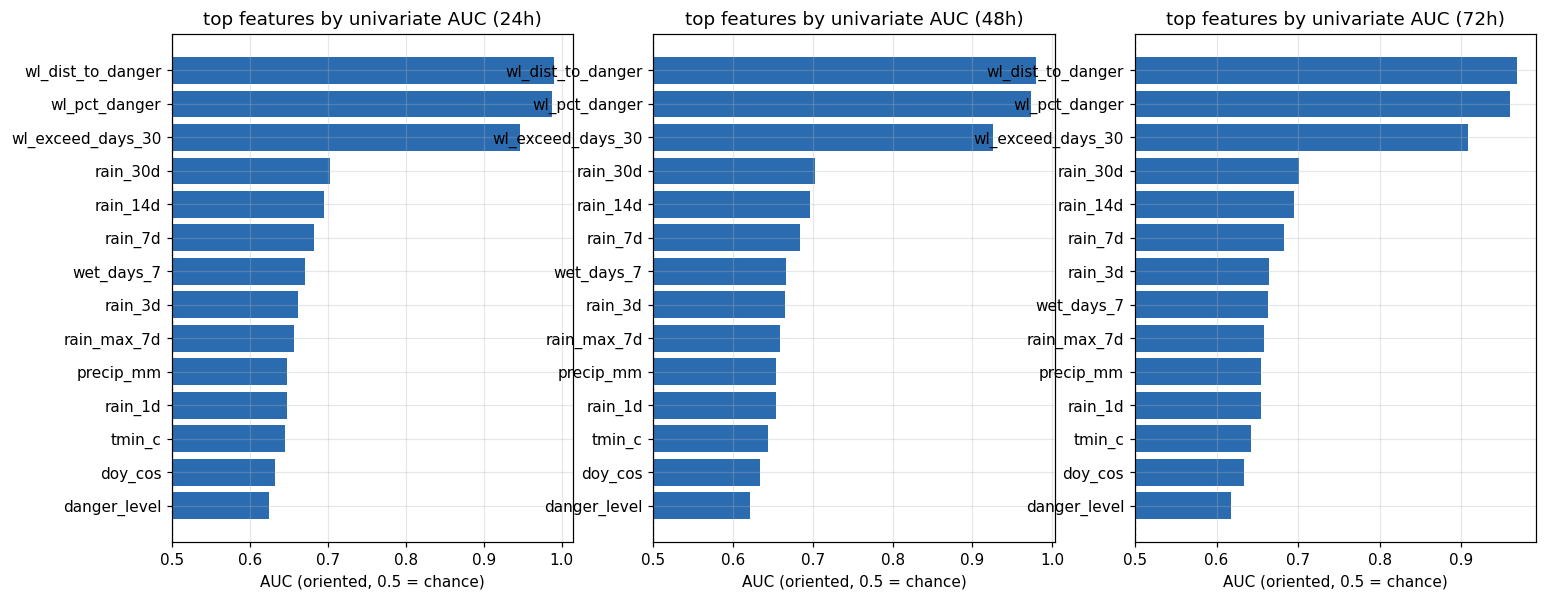

In [9]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.feature_selection import mutual_info_classif

ID_COLS = {"station_id", "name", "river", "basin", "division", "district", "upazilla",
           "date", "source", "day_observed"}
BANNED = {"obs_days_24h", "obs_days_48h", "obs_days_72h"}
LABCOLS = set(LAB.values())
FEATS = [c for c in mr.columns
         if c not in ID_COLS | BANNED | LABCOLS | {"year", "month", "monsoon"}]
check("TF0 feature set honours the information boundary (no obs_days_*, no labels)",
      not (set(FEATS) & (BANNED | LABCOLS)), f"{len(FEATS)} candidate features")

rows = []
for h in HORIZONS:
    s = mr[mr[LAB[h]].notna()]
    y = s[LAB[h]].astype(int)
    for c in FEATS:
        d = s[[c, LAB[h]]].dropna().rename(columns={LAB[h]: "y"})
        if d.y.nunique() < 2 or len(d) < 500:
            rows.append({"h": h, "feature": c, "auc": np.nan, "ks": np.nan,
                         "med0": np.nan, "med1": np.nan, "n": len(d)})
            continue
        auc = roc_auc_score(d.y, d[c])
        if auc < 0.5:
            auc = 1 - auc
        ks = ks_2samp(d.loc[d.y == 0, c], d.loc[d.y == 1, c]).statistic
        rows.append({"h": h, "feature": c, "auc": auc, "ks": ks,
                     "med0": d.loc[d.y == 0, c].median(),
                     "med1": d.loc[d.y == 1, c].median(), "n": len(d)})
tf = pd.DataFrame(rows)
check("TF1 target-feature table complete: every feature scored on every horizon",
      len(tf) == len(FEATS) * 3 and tf.notna().all().all()
      and bool(tf.auc.between(0.5, 1).all()),
      f"{len(tf)} rows, min AUC={tf.auc.min():.3f}")

for h in HORIZONS:
    print(f"\ntop 12 features by univariate AUC ({h}):")
    print(tf[tf.h == h].nlargest(12, "auc")[["feature", "auc", "ks", "med0", "med1", "n"]]
          .round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, h in zip(axes, HORIZONS):
    t = tf[tf.h == h].nlargest(14, "auc")
    ax.barh(t.feature[::-1], t.auc[::-1] - 0.5, left=0.5, color="#2b6cb0")
    ax.axvline(0.5, color="grey", ls=":")
    ax.set_title(f"top features by univariate AUC ({h})")
    ax.set_xlabel("AUC (oriented, 0.5 = chance)")
savefig(fig, "phase5_target_vs_feature.png")
plt.show()

[PASS] TF2 mutual information finite for every feature x horizon  (114 values)
top 10 by mutual information (72h):
  h           feature     mi
72h wl_dist_to_danger 0.1592
72h     wl_pct_danger 0.1570
72h wl_exceed_days_30 0.1047
72h       rain_max_7d 0.0525
72h               lat 0.0461
72h               lon 0.0444
72h      danger_level 0.0385
72h          rain_30d 0.0254
72h            wl_min 0.0229
72h           rain_7d 0.0219


[PASS] TF3 D7 persistence baseline computed for every horizon x year  (27 rows, 9 years)
[PASS] TF4 persistence baseline genuinely informative (pooled AUC > 0.7)  (AUC [0.987, 0.974, 0.959])

D7 PERSISTENCE BASELINE (wl_pct_danger alone) - pooled:
  h      n  base_rate    auc  pr_auc
24h 200559     0.0498 0.9874  0.9042
48h 197748     0.0568 0.9736  0.8692
72h 195174     0.0632 0.9590  0.8359

per year - ROC-AUC:
h       24h    48h    72h
year                     
2017  0.979  0.959  0.940
2019  0.988  0.975  0.960
2020  0.990  0.982  0.974
2021  0.988  0.976  0.964
2022  0.989  0.978  0.965
2023  0.985  0.961  0.940
2024  0.978  0.951  0.923
2025  0.975  0.949  0.917
2026  0.974  0.945  0.919

per year - PR-AUC:
h       24h    48h    72h
year                     
2017  0.916  0.886  0.862
2019  0.886  0.858  0.824
2020  0.959  0.945  0.928
2021  0.925  0.902  0.880
2022  0.906  0.876  0.845
2023  0.628  0.552  0.511
2024  0.802  0.730  0.673
2025  0.733  0.667  0.604
2026  0.723  0.64

figure -> figures\phase5_baseline_by_year.png


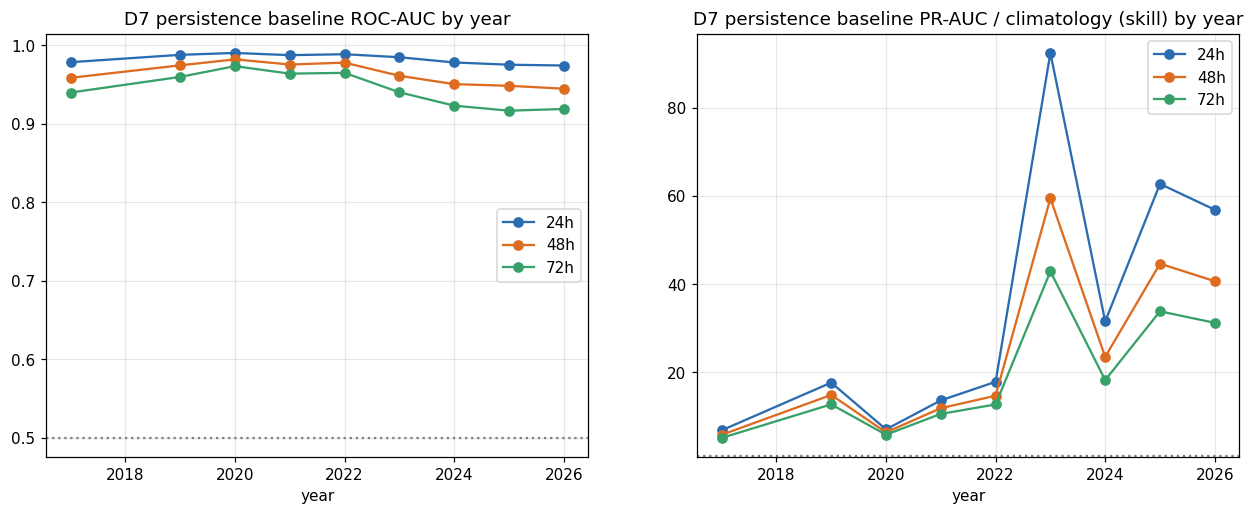

In [10]:
sample = mr.sample(n=min(40_000, len(mr)), random_state=0)
X = sample[FEATS].copy()
for c in FEATS:
    X[c] = X[c].fillna(X[c].median())
mi_rows = []
for h in HORIZONS:
    keep = sample[LAB[h]].notna()
    y = sample.loc[keep, LAB[h]].astype(int)
    mi_vals = mutual_info_classif(X.loc[keep], y, discrete_features=False, n_neighbors=3,
                                  random_state=0)
    for f, m in zip(FEATS, mi_vals):
        mi_rows.append({"h": h, "feature": f, "mi": m})
mi = pd.DataFrame(mi_rows)
check("TF2 mutual information finite for every feature x horizon",
      len(mi) == len(FEATS) * 3 and bool(np.isfinite(mi.mi).all()), f"{len(mi)} values")
print("top 10 by mutual information (72h):")
print(mi[mi.h == "72h"].nlargest(10, "mi").round(4).to_string(index=False))

base_rows = []
for h in HORIZONS:
    s = mr[mr[LAB[h]].notna()]
    for y, g in s.groupby("year"):
        if g[LAB[h]].nunique() < 2 or len(g) < 200:
            base_rows.append({"h": h, "year": y, "n": len(g),
                              "base_rate": g[LAB[h]].mean(),
                              "auc": np.nan, "pr_auc": np.nan})
            continue
        base_rows.append({"h": h, "year": y, "n": len(g), "base_rate": g[LAB[h]].mean(),
                          "auc": roc_auc_score(g[LAB[h]], g.wl_pct_danger),
                          "pr_auc": average_precision_score(g[LAB[h]], g.wl_pct_danger)})
base = pd.DataFrame(base_rows)
pooled = []
for h in HORIZONS:
    s = mr[mr[LAB[h]].notna()]
    pooled.append({"h": h, "n": len(s), "base_rate": s[LAB[h]].mean(),
                   "auc": roc_auc_score(s[LAB[h]], s.wl_pct_danger),
                   "pr_auc": average_precision_score(s[LAB[h]], s.wl_pct_danger)})
pooled = pd.DataFrame(pooled)

n_years = mr.year.nunique()
check("TF3 D7 persistence baseline computed for every horizon x year",
      base.groupby("h").year.nunique().eq(n_years).all()
      and bool(np.isfinite(base.auc).all()), f"{len(base)} rows, {n_years} years")
check("TF4 persistence baseline genuinely informative (pooled AUC > 0.7)",
      bool((pooled.auc > 0.7).all()), f"AUC {pooled.auc.round(3).tolist()}")

print("\nD7 PERSISTENCE BASELINE (wl_pct_danger alone) - pooled:")
print(pooled.round(4).to_string(index=False))
print("\nper year - ROC-AUC:")
print(base.pivot(index="year", columns="h", values="auc").round(3).to_string())
print("\nper year - PR-AUC:")
print(base.pivot(index="year", columns="h", values="pr_auc").round(3).to_string())
note("E4", "D7 persistence baseline (pooled): " + " | ".join(
    f"{r['h']}: AUC {r.auc:.3f}, PR-AUC {r.pr_auc:.3f} vs climatology {r.base_rate:.3f} "
    f"({r.pr_auc / r.base_rate:.1f}x skill)" for _, r in pooled.iterrows()))
note("E5", "best non-persistence features (72h): " + ", ".join(
    f"{r.feature} ({r.auc:.3f})" for _, r in
    tf[(tf.h == "72h") & (tf.feature != "wl_pct_danger")].nlargest(5, "auc").iterrows()))
nr = tf[(tf.h == "72h") & (tf.feature == "n_readings")]
if len(nr) and nr.auc.iloc[0] > 0.6:
    note("E7", f"n_readings (how many 3-hourly readings FFWC published that day) scores "
               f"AUC {nr.auc.iloc[0]:.3f} - the OBSERVATION PROCESS carries hazard signal; "
               f"decide at stage 19/21 whether it is admissible (risk: model learns "
               f"publication policy, not the river)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for h, c in zip(HORIZONS, ["#2b6cb0", "#dd6b20", "#38a169"]):
    r = base[base.h == h].dropna()
    axes[0].plot(r.year, r.auc, marker="o", color=c, label=h)
    axes[1].plot(r.year, r.pr_auc / r.base_rate, marker="o", color=c, label=h)
axes[0].set_title("D7 persistence baseline ROC-AUC by year")
axes[0].axhline(0.5, color="grey", ls=":")
axes[1].set_title("D7 persistence baseline PR-AUC / climatology (skill) by year")
axes[1].axhline(1.0, color="grey", ls=":")
for ax in axes:
    ax.set_xlabel("year"); ax.legend()
savefig(fig, "phase5_baseline_by_year.png")
plt.show()

---
## Stage 17 — Correlation analysis (Phase 8)
Linear (Pearson) and monotone (Spearman) relationships. Per the workflow: high correlation
is **not** importance, low correlation is **not** uselessness — flood response is nonlinear.

[PASS] CO1 correlation matrix symmetric with unit diagonal, no NaN  (38 features)


[PASS] CO2 every feature correlated with every label  (38 features x 3 labels)
strongest linear association with label_72h (pearson):
wl_exceed_days_30    0.612
wl_pct_danger        0.372
wl_dist_to_danger    0.361
rain_7d              0.176
rain_14d             0.173
rain_30d             0.170
rain_3d              0.169
rain_1d              0.148
precip_mm            0.148
rain_max_7d          0.139
wet_days_7           0.132
tmin_c               0.111


figure -> figures\phase5_corr.png


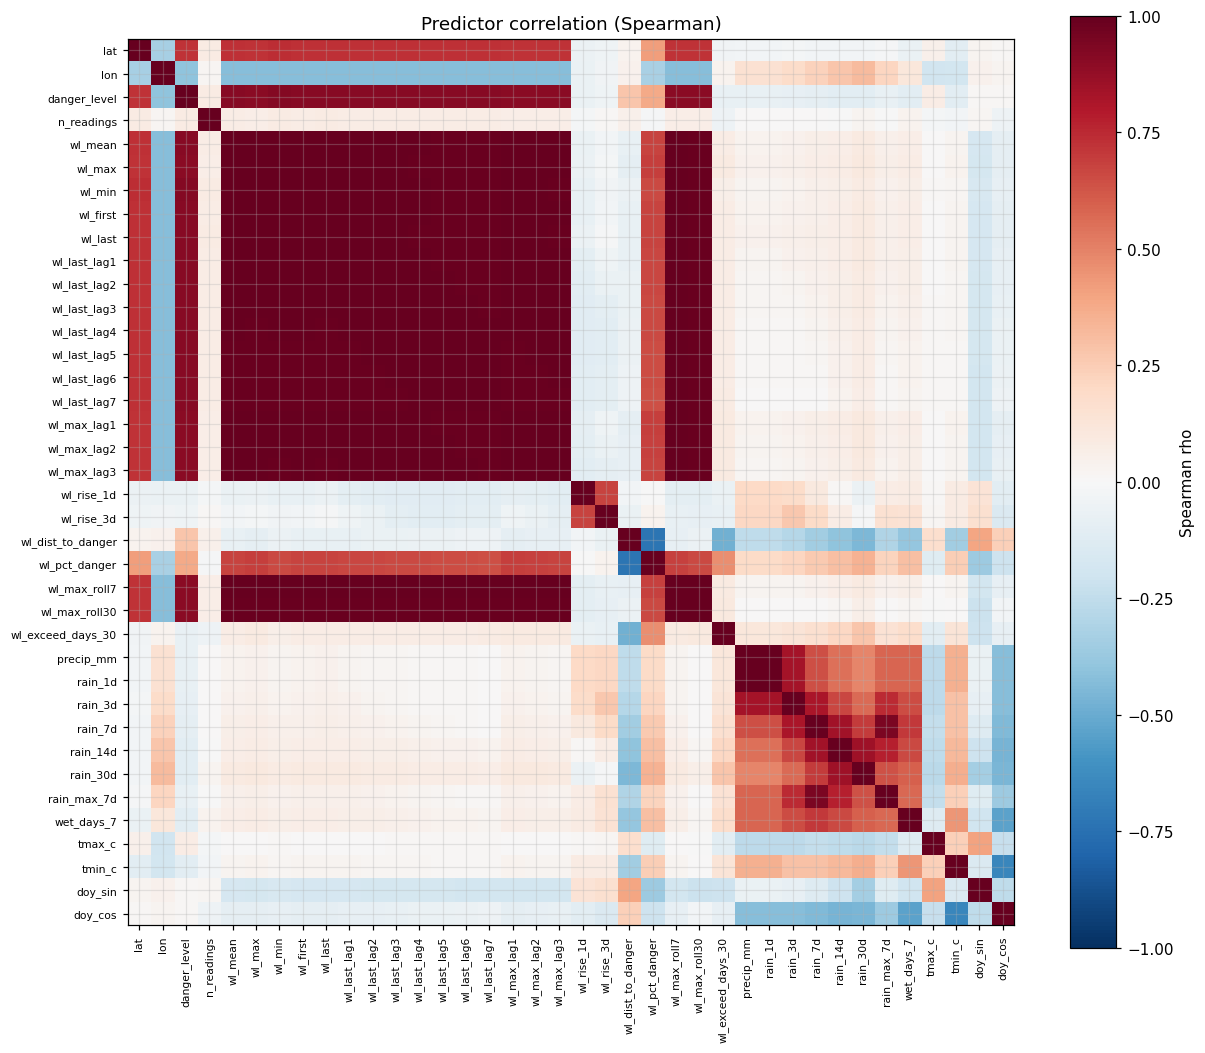

In [11]:
corr_p = mr[FEATS].corr(method="pearson")
corr_s = mr[FEATS].corr(method="spearman")

sym_ok = (np.allclose(corr_p, corr_p.T) and np.allclose(np.diag(corr_p), 1)
          and bool(np.isfinite(corr_p.to_numpy()).all()))
check("CO1 correlation matrix symmetric with unit diagonal, no NaN", sym_ok,
      f"{len(FEATS)} features")

lab_corr = pd.DataFrame({
    h: mr.loc[mr[LAB[h]].notna(), FEATS + [LAB[h]]].corr(method="pearson")[LAB[h]].drop(LAB[h])
    for h in HORIZONS})
check("CO2 every feature correlated with every label", bool(lab_corr.notna().all().all()),
      f"{lab_corr.shape[0]} features x 3 labels")

print("strongest linear association with label_72h (pearson):")
print(lab_corr["72h"].abs().sort_values(ascending=False).head(12).round(3).to_string())

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr_s, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATS))); ax.set_xticklabels(FEATS, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATS))); ax.set_yticklabels(FEATS, fontsize=7)
plt.colorbar(im, ax=ax, label="Spearman rho")
ax.set_title("Predictor correlation (Spearman)")
savefig(fig, "phase5_corr.png")
plt.show()

---
## Stage 18 — Multicollinearity & redundancy (Phase 9)
VIF, near-duplicate pairs, and a concrete keep/drop recommendation. Constants (`G3`) are
confirmed and removed here too. `obs_days_*` are absent by contract, not by luck.

[PASS] MC1 constants identified (G3): day_observed / source are dead in model-ready  (constants=['day_observed', 'source'])
[PASS] MC2 label-adjacent obs_days_* excluded from the feature list
predictor pairs with |Spearman rho| > 0.8: 160   (|rho| > 0.95: 137)
           a            b   rho   abs
   precip_mm      rain_1d 1.000 1.000
     wl_mean     wl_first 0.999 0.999
    wl_first wl_last_lag1 0.999 0.999
     wl_mean       wl_min 0.999 0.999
     wl_mean      wl_last 0.999 0.999
    wl_first      wl_last 0.999 0.999
 wl_max_lag3 wl_max_roll7 0.999 0.999
 wl_max_lag2 wl_max_roll7 0.999 0.999
      wl_max  wl_max_lag1 0.998 0.998
 wl_max_lag1  wl_max_lag2 0.998 0.998
 wl_max_lag2  wl_max_lag3 0.998 0.998
     wl_last wl_last_lag1 0.998 0.998
wl_last_lag2 wl_last_lag3 0.998 0.998
wl_last_lag3 wl_last_lag4 0.998 0.998
wl_last_lag1 wl_last_lag2 0.998 0.998
wl_last_lag6 wl_last_lag7 0.998 0.998
wl_last_lag4 wl_last_lag5 0.998 0.998
wl_last_lag5 wl_last_lag6 0.998 0.998
     wl_mean wl_l

[PASS] MC3 VIF computed for every non-constant feature (20k-row sample)  (max VIF=1000000000)


[PASS] MC4 drop list produced; residual VIF <= 10 after iterative pruning  (max VIF after pruning=5.4; dropped 23)

recommended drop (23): ['danger_level', 'day_observed', 'rain_1d', 'rain_7d', 'source', 'wl_dist_to_danger', 'wl_first', 'wl_last', 'wl_last_lag1', 'wl_last_lag2', 'wl_last_lag3', 'wl_last_lag4', 'wl_last_lag5', 'wl_last_lag6', 'wl_last_lag7', 'wl_max', 'wl_max_lag1', 'wl_max_lag2', 'wl_max_lag3', 'wl_max_roll30', 'wl_max_roll7', 'wl_mean', 'wl_min']
recommended keep (17): ['lat', 'lon', 'n_readings', 'wl_rise_1d', 'wl_rise_3d', 'wl_pct_danger', 'wl_exceed_days_30', 'precip_mm', 'rain_3d', 'rain_14d', 'rain_30d', 'rain_max_7d', 'wet_days_7', 'tmax_c', 'tmin_c', 'doy_sin', 'doy_cos']
[NOTE E6] redundancy: 160 predictor pairs |rho|>0.8, 137 near-duplicates |rho|>0.95; VIF>10 for ['danger_level', 'precip_mm', 'rain_1d', 'rain_7d', 'wl_dist_to_danger', 'wl_first', 'wl_last', 'wl_last_lag1', 'wl_last_lag2', 'wl_last_lag3', 'wl_last_lag4', 'wl_last_lag5', 'wl_last_lag6', 'wl_la

figure -> figures\phase5_vif.png


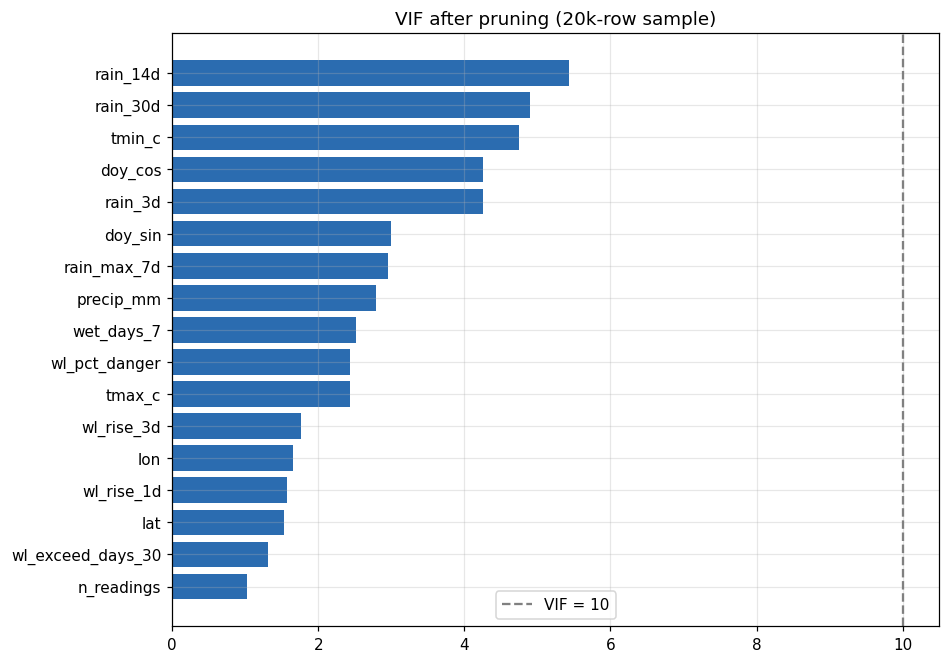

In [12]:
const = [c for c in mr.columns if mr[c].nunique(dropna=False) <= 1]
check("MC1 constants identified (G3): day_observed / source are dead in model-ready",
      set(const) >= {"day_observed", "source"}, f"constants={const}")
check("MC2 label-adjacent obs_days_* excluded from the feature list",
      not (set(FEATS) & BANNED))

iu = np.triu_indices(len(FEATS), k=1)
pairs = pd.DataFrame({"a": corr_s.index[iu[0]], "b": corr_s.columns[iu[1]],
                      "rho": corr_s.to_numpy()[iu]})
pairs["abs"] = pairs.rho.abs()
hi = pairs[pairs["abs"] > 0.8].sort_values("abs", ascending=False)
dup = pairs[pairs["abs"] > 0.95].sort_values("abs", ascending=False)
print(f"predictor pairs with |Spearman rho| > 0.8: {len(hi)}   (|rho| > 0.95: {len(dup)})")
print(hi.head(25).round(3).to_string(index=False))

from sklearn.linear_model import LinearRegression
vcols = [c for c in FEATS if c not in const]
vs = mr[vcols].sample(n=20_000, random_state=0).copy()
for c in vcols:
    vs[c] = vs[c].fillna(vs[c].median())

def vif_table(df):
    out = {}
    for c in df.columns:
        X = df.drop(columns=[c]).to_numpy()
        y = df[c].to_numpy()
        r2 = LinearRegression().fit(X, y).score(X, y)
        out[c] = 1.0 / max(1e-9, 1 - r2)
    return pd.Series(out).sort_values(ascending=False)

v1 = vif_table(vs)
check("MC3 VIF computed for every non-constant feature (20k-row sample)",
      len(v1) == len(vcols) and bool(np.isfinite(v1).all()), f"max VIF={v1.max():.0f}")

drop = set(const)
for _, r in dup.iterrows():
    if r.a in vcols and r.b in vcols:
        drop.add(r.b)
kept = [c for c in vcols if c not in drop]
v2 = vif_table(vs[kept])
for _ in range(4):
    fat = v2[v2 > 10]
    if fat.empty:
        break
    drop.update(fat.index)
    kept = [c for c in kept if c not in fat.index]
    v2 = vif_table(vs[kept])
check("MC4 drop list produced; residual VIF <= 10 after iterative pruning",
      bool((v2 <= 10).all()), f"max VIF after pruning={v2.max():.1f}; dropped {len(drop)}")

print(f"\nrecommended drop ({len(drop)}): {sorted(drop)}")
print(f"recommended keep ({len(kept)}): {kept}")
note("E6", f"redundancy: {len(hi)} predictor pairs |rho|>0.8, {len(dup)} near-duplicates "
           f"|rho|>0.95; VIF>10 for {sorted(v1[v1 > 10].index)}; iterative pruning leaves "
           f"{len(kept)} features (constants {const} dropped; obs_days_* never admitted)")

fig, ax = plt.subplots(figsize=(9, 7))
v2s = v2.sort_values()
ax.barh(v2s.index, v2s.values, color=np.where(v2s > 10, "#c53030", "#2b6cb0"))
ax.axvline(10, color="grey", ls="--", label="VIF = 10")
ax.set_title("VIF after pruning (20k-row sample)"); ax.legend()
savefig(fig, "phase5_vif.png")
plt.show()

In [13]:
reg = pd.DataFrame(checks)
print(reg.to_string(index=False))
print()
fnd = pd.DataFrame(findings)
print(fnd.to_string(index=False) if len(fnd) else "(no findings)")
n_pass = int((reg.result == "PASS").sum())
print(f"\n{n_pass} PASS / {int((reg.result == 'FAIL').sum())} FAIL  |  {len(fnd)} findings recorded")
assert (reg.result == "PASS").all(), "EDA checks failed"
print("RESULT: ALL CHECKS PASSED")

                                                                         check result                                detail
                           U1 univariate stats finite for all 12 key variables   PASS               198125..200665 non-null
                                  U2 every key variable non-constant (std > 0)   PASS                                      
       TM1 monthly frequency table partitions every labelled row (per horizon)   PASS                         24h n=200,559
         TM2 D1 monsoon flag (JJAS) partitions every labelled row exactly once   PASS                                      
TM3 D5 drift decomposition built for every horizon x year (all vs fixed panel)   PASS            27 rows, panel=31 stations
          TM4 D6 observed-day rates computed for all 12 months (2018 excluded)   PASS                                      
  TM5 D6 rain compared on observed vs unobserved days (KS on >=1000 rows each)   PASS                                      
        